In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("Set2")
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:.2f}')

path = '/content/drive/MyDrive/course_data/'

orders = pd.read_csv(path + 'olist_orders_dataset.csv')
items = pd.read_csv(path + 'olist_order_items_dataset.csv')
products = pd.read_csv(path + 'olist_products_dataset.csv')
customers = pd.read_csv(path + 'olist_customers_dataset.csv')
translations = pd.read_csv(path + 'product_category_name_translation.csv')

print("Усі 5 таблиць успішно завантажені!")


Усі 5 таблиць успішно завантажені!


In [22]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


--- Orders ---
Розмірність: 99441 рядків, 8 стовпців
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB
None 

--- Order Items ---
Розмірність: 112650 рядків, 7 стовпців
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Nul

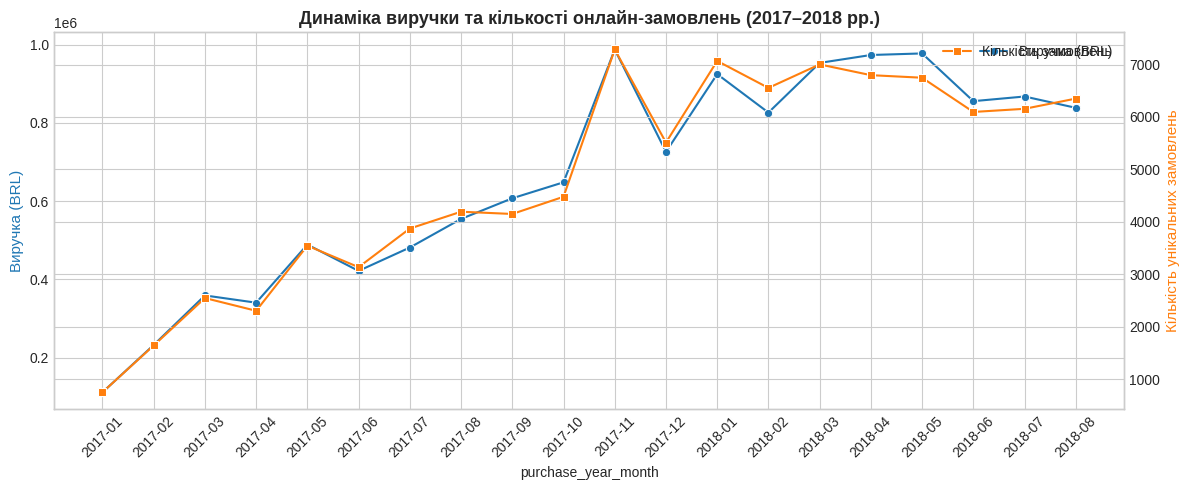

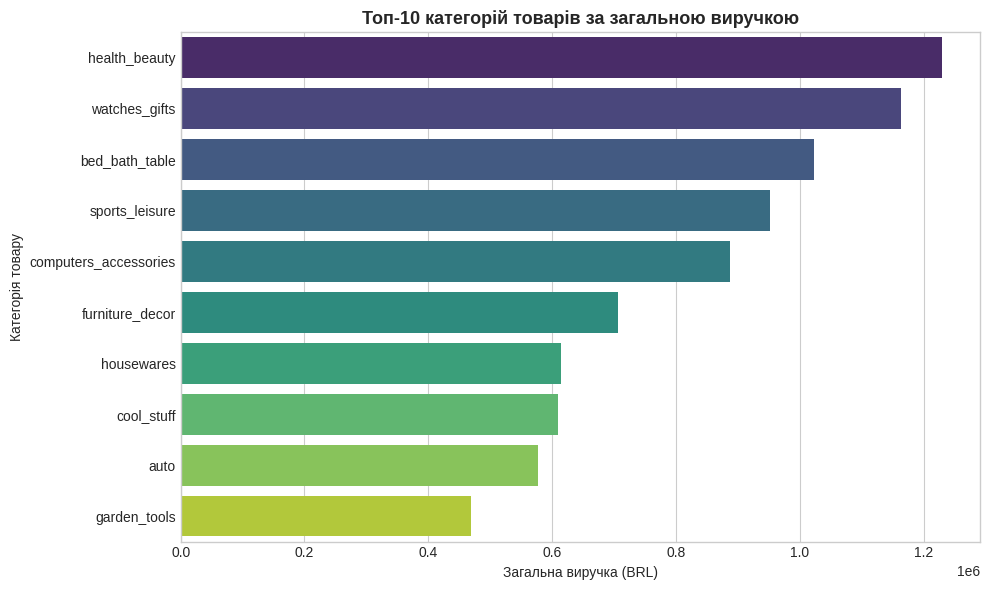

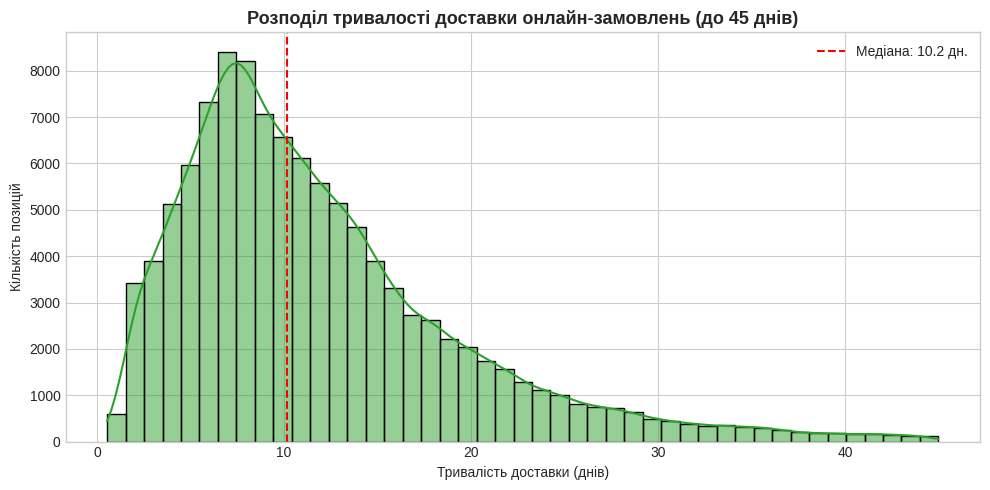

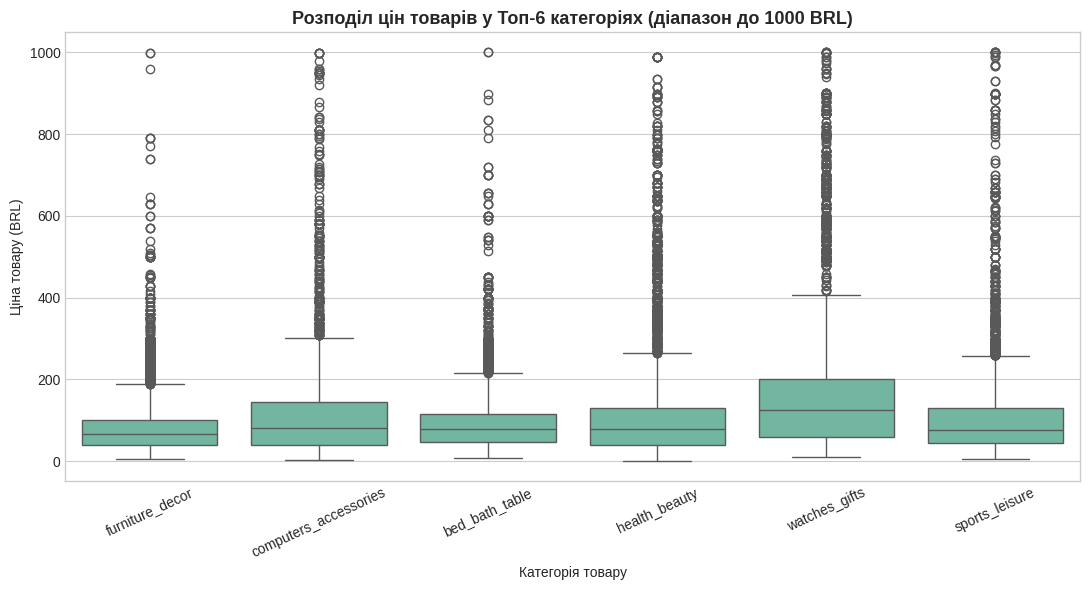

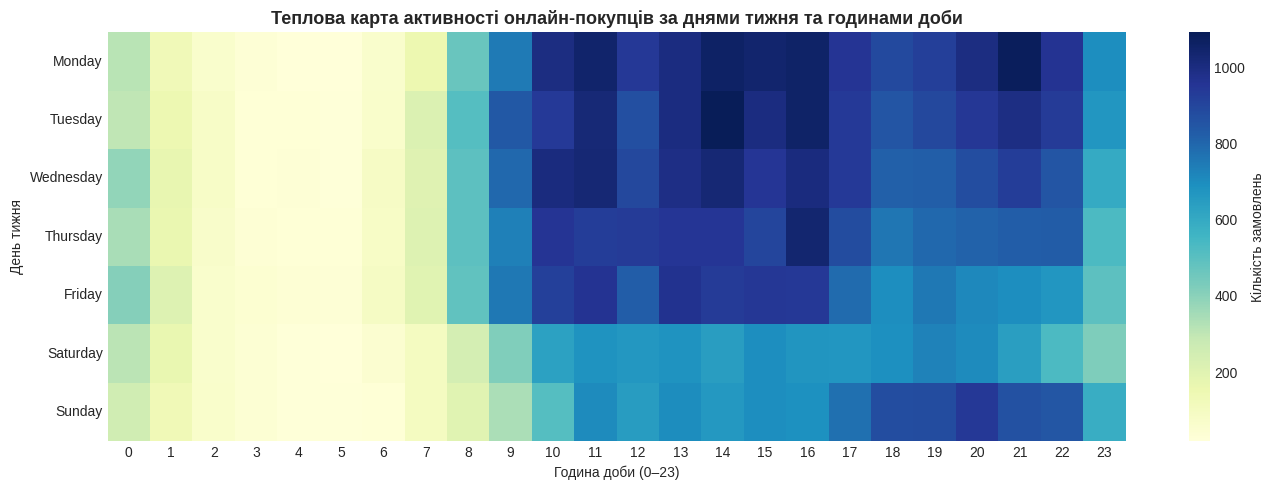

In [23]:
# ==============================================================================
# ЕТАП 2. ПЕРВИННЕ ДОСЛІДЖЕННЯ ДАНИХ
# ==============================================================================
datasets = {
    'Orders': orders,
    'Order Items': items,
    'Products': products,
    'Customers': customers
}

for name, df in datasets.items():
    print(f"--- {name} ---")
    print(f"Розмірність: {df.shape[0]} рядків, {df.shape[1]} стовпців")
    print(df.info(), "\n")

# ==============================================================================
# ЕТАП 3. ПОПЕРЕДНЄ ОПРАЦЮВАННЯ ТА ОЧИЩЕННЯ ДАНИХ
# ==============================================================================
for name, df in datasets.items():
    dups = df.duplicated().sum()
    print(f"Дублікатів у {name}: {dups}")
    if dups > 0:
        df.drop_duplicates(inplace=True)

print("\nПропущені значення у таблиці Orders до очищення:")
print(orders.isna().sum()[orders.isna().sum() > 0])

orders_clean = orders[orders['order_status'] == 'delivered'].copy()
orders_clean.dropna(subset=['order_delivered_customer_date', 'order_approved_at'], inplace=True)

date_cols = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]
for col in date_cols:
    orders_clean[col] = pd.to_datetime(orders_clean[col])

products_clean = products.merge(translations, on='product_category_name', how='left')
products_clean['product_category_name_english'].fillna('other', inplace=True)

items_clean = items[items['price'] > 0].copy()

# ==============================================================================
# ЕТАП 4. ОБ'ЄДНАННЯ ТАБЛИЦЬ ТА СТВОРЕННЯ АНАЛІТИЧНИХ ОЗНАК
# ==============================================================================
df_merged = orders_clean.merge(items_clean, on='order_id', how='inner')
df_merged = df_merged.merge(
    products_clean[['product_id', 'product_category_name_english', 'product_weight_g']],
    on='product_id',
    how='left'
)
df_merged = df_merged.merge(
    customers[['customer_id', 'customer_unique_id', 'customer_city', 'customer_state']],
    on='customer_id',
    how='left'
)

df_merged['total_item_value'] = df_merged['price'] + df_merged['freight_value']
df_merged['freight_ratio'] = (df_merged['freight_value'] / df_merged['total_item_value']) * 100
df_merged['delivery_days'] = (
    df_merged['order_delivered_customer_date'] - df_merged['order_purchase_timestamp']
).dt.total_seconds() / 86400
df_merged['delivery_delay_days'] = (
    df_merged['order_delivered_customer_date'] - df_merged['order_estimated_delivery_date']
).dt.days

df_merged['purchase_year_month'] = df_merged['order_purchase_timestamp'].dt.to_period('M').astype(str)
df_merged['purchase_dayofweek'] = df_merged['order_purchase_timestamp'].dt.day_name()
df_merged['purchase_hour'] = df_merged['order_purchase_timestamp'].dt.hour

df_merged['order_value_segment'] = pd.cut(
    df_merged['total_item_value'],
    bins=[0, 50, 150, 500, np.inf],
    labels=['Низький (<50)', 'Середній (50-150)', 'Високий (150-500)', 'Преміум (>500)']
)

df_merged = df_merged[
    (df_merged['order_purchase_timestamp'] >= '2017-01-01') &
    (df_merged['order_purchase_timestamp'] < '2018-09-01')
]

# Збереження очищеного файлу прямо у вашу папку course_data на Google Диску
df_merged.to_csv(path + 'ecommerce_cleaned.csv', index=False)
print("\nОчищений файл ecommerce_cleaned.csv збережено в папку course_data!")

# ==============================================================================
# ЕТАП 5. СТАТИСТИЧНИЙ ТА АНАЛІТИЧНИЙ АНАЛІЗ
# ==============================================================================
print("\nОписова статистика:")
print(df_merged[['price', 'freight_value', 'total_item_value', 'delivery_days']].describe(
    percentiles=[0.25, 0.5, 0.75, 0.95]
))

category_stats = df_merged.groupby('product_category_name_english').agg(
    orders_count=('order_id', 'nunique'),
    items_sold=('order_item_id', 'count'),
    total_revenue=('price', 'sum'),
    avg_price=('price', 'mean'),
    median_delivery=('delivery_days', 'median')
).reset_index()

category_stats['revenue_share_%'] = (category_stats['total_revenue'] / category_stats['total_revenue'].sum()) * 100
top10_categories = category_stats.nlargest(10, 'total_revenue')
print("\nТоп-10 категорій за обсягом виручки:")
print(top10_categories)

top5_states = df_merged['customer_state'].value_counts().nlargest(5).index
pivot_state_segment = pd.pivot_table(
    df_merged[df_merged['customer_state'].isin(top5_states)],
    values='total_item_value',
    index='customer_state',
    columns='order_value_segment',
    aggfunc='count',
    fill_value=0
)
print("\nЗведена таблиця кількості позицій за штатами та ціновими сегментами:")
print(pivot_state_segment)

corr_cols = ['price', 'freight_value', 'product_weight_g', 'delivery_days', 'freight_ratio']
print("\nКореляційна матриця (Спірмена):")
print(df_merged[corr_cols].corr(method='spearman'))

# ==============================================================================
# ЕТАП 6. ВІЗУАЛІЗАЦІЯ ДАНИХ (ЗБЕРЕЖЕННЯ НА GOOGLE ДИСК)
# ==============================================================================
# Графік 1
monthly_trend = df_merged.groupby('purchase_year_month').agg(
    revenue=('price', 'sum'),
    orders=('order_id', 'nunique')
).reset_index()

fig, ax1 = plt.subplots(figsize=(12, 5))
sns.lineplot(data=monthly_trend, x='purchase_year_month', y='revenue', marker='o', color='#1f77b4', ax=ax1, label='Виручка (BRL)')
ax1.set_ylabel('Виручка (BRL)', color='#1f77b4', fontsize=11)
ax1.tick_params(axis='x', rotation=45)

ax2 = ax1.twinx()
sns.lineplot(data=monthly_trend, x='purchase_year_month', y='orders', marker='s', color='#ff7f0e', ax=ax2, label='Кількість замовлень')
ax2.set_ylabel('Кількість унікальних замовлень', color='#ff7f0e', fontsize=11)
plt.title('Динаміка виручки та кількості онлайн-замовлень (2017–2018 рр.)', fontsize=13, fontweight='bold')
fig.tight_layout()
plt.savefig(path + '01_monthly_dynamics.png', dpi=300)
plt.show()

# Графік 2
plt.figure(figsize=(10, 6))
sns.barplot(data=top10_categories, x='total_revenue', y='product_category_name_english', palette='viridis')
plt.title('Топ-10 категорій товарів за загальною виручкою', fontsize=13, fontweight='bold')
plt.xlabel('Загальна виручка (BRL)')
plt.ylabel('Категорія товару')
plt.tight_layout()
plt.savefig(path + '02_top10_categories.png', dpi=300)
plt.show()

# Графік 3
plt.figure(figsize=(10, 5))
sns.histplot(df_merged[df_merged['delivery_days'] <= 45]['delivery_days'], bins=45, kde=True, color='#2ca02c')
plt.axvline(df_merged['delivery_days'].median(), color='red', linestyle='--', label=f"Медіана: {df_merged['delivery_days'].median():.1f} дн.")
plt.title('Розподіл тривалості доставки онлайн-замовлень (до 45 днів)', fontsize=13, fontweight='bold')
plt.xlabel('Тривалість доставки (днів)')
plt.ylabel('Кількість позицій')
plt.legend()
plt.tight_layout()
plt.savefig(path + '03_delivery_distribution.png', dpi=300)
plt.show()

# Графік 4
top6_names = top10_categories['product_category_name_english'].head(6).tolist()
plt.figure(figsize=(11, 6))
sns.boxplot(
    data=df_merged[(df_merged['product_category_name_english'].isin(top6_names)) & (df_merged['price'] <= 1000)],
    x='product_category_name_english',
    y='price'
)
plt.title('Розподіл цін товарів у Топ-6 категоріях (діапазон до 1000 BRL)', fontsize=13, fontweight='bold')
plt.xlabel('Категорія товару')
plt.ylabel('Ціна товару (BRL)')
plt.xticks(rotation=25)
plt.tight_layout()
plt.savefig(path + '04_price_boxplot.png', dpi=300)
plt.show()

# Графік 5
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
heatmap_data = pd.pivot_table(
    df_merged,
    values='order_id',
    index='purchase_dayofweek',
    columns='purchase_hour',
    aggfunc='nunique'
).reindex(days_order)

plt.figure(figsize=(14, 5))
sns.heatmap(heatmap_data, cmap='YlGnBu', annot=False, cbar_kws={'label': 'Кількість замовлень'})
plt.title('Теплова карта активності онлайн-покупців за днями тижня та годинами доби', fontsize=13, fontweight='bold')
plt.xlabel('Година доби (0–23)')
plt.ylabel('День тижня')
plt.tight_layout()
plt.savefig(path + '05_activity_heatmap.png', dpi=300)
plt.show()